# 🎶 Music Generation with Transformers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidADSP/Generative_Deep_Learning_2nd_Edition/blob/main/notebooks/11_music/01_transformer/transformer.ipynb)

In this notebook, we'll walk through the steps required to train your own Transformer model to generate music in the style of the Bach cello suites

In [26]:
# Setup for Google Colab and local environments
import os
import sys

# Python 3.12+ compatibility shim for 'imp' (used by legacy autoreload)
if "imp" not in sys.modules:
    try:
        import imp
    except ImportError:
        import importlib
        import types

        _imp = types.ModuleType("imp")
        _imp.reload = importlib.reload
        sys.modules["imp"] = _imp

# 1. If running in Google Colab, clone the repository and navigate into it
if "google.colab" in sys.modules:
    if os.path.exists("/content"):
        %cd /content
    if not os.path.exists("Generative_Deep_Learning_2nd_Edition"):
        !git clone https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition.git
    %cd /content/Generative_Deep_Learning_2nd_Edition
    if os.path.abspath(".") not in sys.path:
        sys.path.append(os.path.abspath("."))

# 2. Add repository root to sys.path if running locally outside repository root
repo_root = None
for candidate in [
    os.path.abspath(os.path.join(os.getcwd(), "../../..")),
    os.path.abspath(os.getcwd()),
    os.path.abspath("/content/Generative_Deep_Learning_2nd_Edition"),
    "/app",
]:
    if os.path.exists(os.path.join(candidate, "notebooks")):
        repo_root = candidate
        break
if repo_root is None:
    repo_root = os.path.abspath(os.path.join(os.getcwd(), "../../.."))

if repo_root not in sys.path:
    sys.path.append(repo_root)

# 3. Add notebook directory to sys.path for local module imports (transformer_utils)
notebook_dir = os.path.join(repo_root, "notebooks", "11_music", "01_transformer")
if os.path.exists(notebook_dir) and notebook_dir not in sys.path:
    sys.path.append(notebook_dir)


/content
/content/Generative_Deep_Learning_2nd_Edition


In [27]:
# Python 3.12+ compatibility shim for 'imp' (used by legacy autoreload)
import sys
if "imp" not in sys.modules:
    try:
        import imp
    except ImportError:
        import importlib
        import types

        _imp = types.ModuleType("imp")
        _imp.reload = importlib.reload
        sys.modules["imp"] = _imp

# Enable autoreload if available and supported
try:
    %load_ext autoreload
    %autoreload 2
except Exception:
    pass

import os
import glob
import numpy as np
import time
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models, losses, callbacks

# Install music21 if not already installed (e.g. in Colab)
try:
    import music21
except ImportError:
    !pip install music21
    import music21

from transformer_utils import (
    parse_midi_files,
    load_parsed_files,
    get_midi_note,
    SinePositionEncoding,
)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {bool(tf.config.list_physical_devices('GPU'))}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
TensorFlow version: 2.21.0
GPU available: True


## 0. Parameters <a name="parameters"></a>

In [28]:
PARSE_MIDI_FILES = True
PARSED_DATA_PATH = os.path.join(
    repo_root, "notebooks", "11_music", "01_transformer", "parsed_data"
)
os.makedirs(PARSED_DATA_PATH, exist_ok=True)
DATASET_REPETITIONS = 1

SEQ_LEN = 50
EMBEDDING_DIM = 256
KEY_DIM = 256
N_HEADS = 5
DROPOUT_RATE = 0.3
FEED_FORWARD_DIM = 256
LOAD_MODEL = False

# optimization
EPOCHS = 50
BATCH_SIZE = 256

GENERATE_LEN = 50


## 1. Prepare the Data

In [29]:
# Resolve dataset path across Docker, local, Kaggle, or Colab environments
data_dir = None
candidate_dirs = [
    os.path.join(repo_root, "data", "bach-cello"),
    "/app/data/bach-cello",
    os.path.abspath("./data/bach-cello"),
    os.path.abspath("../../../data/bach-cello"),
    "/kaggle/input/bach-cello",
    "/content/data/bach-cello",
]

for candidate in candidate_dirs:
    if os.path.exists(candidate) and len(glob.glob(os.path.join(candidate, "*.mid"))) > 0:
        data_dir = candidate
        break

if data_dir is None:
    data_dir = os.path.join(repo_root, "data", "bach-cello")

file_list = glob.glob(os.path.join(data_dir, "*.mid"))

# If dataset is missing, automatically download Bach cello suites MIDI files
if not file_list:
    print(f"Dataset not found at {data_dir}. Attempting to download Bach cello suites MIDI files...")
    os.makedirs(data_dir, exist_ok=True)
    import urllib.request

    midi_filenames = [
        f"cs{suite}-{part}{m}.mid"
        for suite, m_list in [
            (1, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "men"), ("6", "gig")]),
            (2, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "men"), ("6", "gig")]),
            (3, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "bou"), ("6", "gig")]),
            (4, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "bou"), ("6", "gig")]),
            (5, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "gav"), ("6", "gig")]),
            (6, [("1", "pre"), ("2", "all"), ("3", "cou"), ("4", "sar"), ("5", "gav"), ("6", "gig")]),
        ]
        for part, m in m_list
    ]

    downloaded = 0
    for fname in midi_filenames:
        dest = os.path.join(data_dir, fname)
        if not os.path.exists(dest):
            for base_url in ["https://www.jsbach.net/midi/", "http://www.jsbach.net/midi/"]:
                try:
                    req = urllib.request.Request(f"{base_url}{fname}", headers={"User-Agent": "Mozilla/5.0"})
                    with urllib.request.urlopen(req, timeout=10) as resp:
                        with open(dest, "wb") as f_out:
                            f_out.write(resp.read())
                    downloaded += 1
                    break
                except Exception:
                    continue

    file_list = glob.glob(os.path.join(data_dir, "*.mid"))
    if not file_list:
        raise FileNotFoundError(
            f"Could not find or automatically download Bach cello MIDI files at '{data_dir}'.\n"
            f"Please run: bash scripts/download.sh cellosuites"
        )
    print(f"Downloaded and saved {len(file_list)} MIDI files to {data_dir}")

print(f"Found {len(file_list)} midi files")


Found 36 midi files


In [30]:
parser = music21.converter

In [31]:
example_score = (
    music21.converter.parse(file_list[1]).splitAtQuarterLength(12)[0].chordify()
)

In [32]:
try:
    example_score.show()
except Exception as e:
    print(f"Graphical sheet music viewer not available ({e}). Showing as text:")
    example_score.show("text")


Graphical sheet music viewer not available (Cannot find a path to the 'mscore' file at /usr/bin/mscore3 -- download MuseScore). Showing as text:
{0.0} <music21.metadata.Metadata object at 0x7c3b2bd741d0>
{0.0} <music21.stream.Measure 1 offset=0.0>
    {0.0} <music21.instrument.Violoncello 'Solo Cello: Solo Cello'>
    {0.0} <music21.instrument.Violoncello 'Violoncello'>
    {0.0} <music21.clef.BassClef>
    {0.0} <music21.tempo.MetronomeMark Quarter=150>
    {0.0} <music21.key.Key of G major>
    {0.0} <music21.meter.TimeSignature 3/4>
    {0.0} <music21.chord.Chord G2>
    {0.5} <music21.chord.Chord D3>
    {1.0} <music21.chord.Chord B3>
    {2.0} <music21.chord.Chord A3>
    {2.5} <music21.chord.Chord B3>
    {2.75} <music21.chord.Chord C4>
{3.0} <music21.stream.Measure 2 offset=3.0>
    {0.0} <music21.chord.Chord B3>
    {0.5} <music21.chord.Chord A3>
    {1.0} <music21.chord.Chord G3>
    {1.5} <music21.chord.Chord F#3>
    {2.0} <music21.chord.Chord G3>
    {2.5} <music21.chord.Ch

In [33]:
example_score.show("text")

{0.0} <music21.metadata.Metadata object at 0x7c3b2bd741d0>
{0.0} <music21.stream.Measure 1 offset=0.0>
    {0.0} <music21.instrument.Violoncello 'Solo Cello: Solo Cello'>
    {0.0} <music21.instrument.Violoncello 'Violoncello'>
    {0.0} <music21.clef.BassClef>
    {0.0} <music21.tempo.MetronomeMark Quarter=150>
    {0.0} <music21.key.Key of G major>
    {0.0} <music21.meter.TimeSignature 3/4>
    {0.0} <music21.chord.Chord G2>
    {0.5} <music21.chord.Chord D3>
    {1.0} <music21.chord.Chord B3>
    {2.0} <music21.chord.Chord A3>
    {2.5} <music21.chord.Chord B3>
    {2.75} <music21.chord.Chord C4>
{3.0} <music21.stream.Measure 2 offset=3.0>
    {0.0} <music21.chord.Chord B3>
    {0.5} <music21.chord.Chord A3>
    {1.0} <music21.chord.Chord G3>
    {1.5} <music21.chord.Chord F#3>
    {2.0} <music21.chord.Chord G3>
    {2.5} <music21.chord.Chord D3>
{6.0} <music21.stream.Measure 3 offset=6.0>
    {0.0} <music21.chord.Chord E3>
    {0.5} <music21.chord.Chord G3>
    {1.0} <music21.chor

In [34]:
if PARSE_MIDI_FILES:
    notes, durations = parse_midi_files(
        file_list, parser, SEQ_LEN + 1, PARSED_DATA_PATH
    )
else:
    notes, durations = load_parsed_files(PARSED_DATA_PATH)


1 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs4-4sar.mid


/tmp/ipykernel_1303/1356734653.py:2: Music21DeprecationWarning: .flat is deprecated.  Call .flatten() instead
  notes, durations = parse_midi_files(


320 notes parsed
2 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs1-5men.mid
967 notes parsed
3 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs6-1pre.mid
2309 notes parsed
4 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs3-1pre.mid
3290 notes parsed
5 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs2-4sar.mid
3627 notes parsed
6 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs5-2all.mid
4319 notes parsed
7 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs1-2all.mid
5240 notes parsed
8 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs4-6gig.mid
6211 notes parsed
9 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs4-1pre.mid
7028 notes parsed
10 Parsing /content/Generative_Deep_Learning_2nd_Edition/data/bach-cello/cs1-4sar.mid
7291 notes parsed
11 Parsing /content/Generative_Deep_Learning_2nd_Edition

In [35]:
example_notes = notes[658]
example_durations = durations[658]
print("\nNotes string\n", example_notes, "...")
print("\nDuration string\n", example_durations, "...")


Notes string
 E2 D2 G3 F#3 D3 F#3 A3 C4 E-4 D4 C4 B-3 A3 B-3 G3 C3 E3 G3 B-3 D4 C4 B-3 A3 G3 A3 F3 E-3 D3 F3 B-3 A3 B-3 D3 E-3 G3 B-3 A3 B-3 D4 C4 E-4 D4 B-3 F3 A3 B-3 F3 D3 F3 B-2 B2 ...

Duration string
 0.5 0.5 0.5 2.0 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 1.0 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 0.5 1.0 0.5 ...


## 2. Tokenize the data <a name="tokenize"></a>

In [36]:
def create_dataset(elements):
    ds = (
        tf.data.Dataset.from_tensor_slices(elements)
        .batch(BATCH_SIZE, drop_remainder=True)
        .shuffle(1000)
    )
    vectorize_layer = layers.TextVectorization(
        standardize=None, output_mode="int"
    )
    vectorize_layer.adapt(ds)
    vocab = vectorize_layer.get_vocabulary()
    return ds, vectorize_layer, vocab


notes_seq_ds, notes_vectorize_layer, notes_vocab = create_dataset(notes)
durations_seq_ds, durations_vectorize_layer, durations_vocab = create_dataset(
    durations
)
seq_ds = tf.data.Dataset.zip((notes_seq_ds, durations_seq_ds))

In [37]:
# Display the same example notes and durations converted to ints
example_tokenised_notes = notes_vectorize_layer(example_notes)
example_tokenised_durations = durations_vectorize_layer(example_durations)
print("{:10} {:10}".format("note token", "duration token"))
for i, (note_int, duration_int) in enumerate(
    zip(
        example_tokenised_notes.numpy()[:11],
        example_tokenised_durations.numpy()[:11],
    )
):
    print(f"{note_int:10}{duration_int:10}")

note token duration token
        31         3
        30         3
         2         3
        12        11
         4         3
        12         3
         3         3
         6         3
        23         3
         7         3
         6         3


In [38]:
notes_vocab_size = len(notes_vocab)
durations_vocab_size = len(durations_vocab)

# Display some token:note mappings
print(f"\nNOTES_VOCAB: length = {len(notes_vocab)}")
for i, note in enumerate(notes_vocab[:10]):
    print(f"{i}: {note}")

print(f"\nDURATIONS_VOCAB: length = {len(durations_vocab)}")
# Display some token:duration mappings
for i, note in enumerate(durations_vocab[:10]):
    print(f"{i}: {note}")


NOTES_VOCAB: length = 59
0: 
1: [UNK]
2: G3
3: A3
4: D3
5: F3
6: C4
7: D4
8: E3
9: B3

DURATIONS_VOCAB: length = 24
0: 
1: [UNK]
2: 0.25
3: 0.5
4: 1.0
5: 1/3
6: 0.75
7: 1/12
8: 1.5
9: 0.0


## 3. Create the Training Set <a name="create"></a>

In [39]:
# Create the training set of sequences and the same sequences shifted by one note
def prepare_inputs(notes, durations):
    notes = tf.expand_dims(notes, -1)
    durations = tf.expand_dims(durations, -1)
    tokenized_notes = notes_vectorize_layer(notes)
    tokenized_durations = durations_vectorize_layer(durations)
    x = (tokenized_notes[:, :-1], tokenized_durations[:, :-1])
    y = (tokenized_notes[:, 1:], tokenized_durations[:, 1:])
    return x, y


ds = seq_ds.map(prepare_inputs).repeat(DATASET_REPETITIONS)

In [40]:
example_input_output = ds.take(1).get_single_element()
print(example_input_output)

((<tf.Tensor: shape=(256, 50), dtype=int64, numpy=
array([[19, 13, 10, ...,  3,  3,  3],
       [13, 10,  4, ...,  3,  3,  3],
       [10,  4, 13, ...,  3,  3,  3],
       ...,
       [11, 11, 11, ...,  2,  3, 17],
       [11, 11, 11, ...,  3, 17,  7],
       [11, 11,  5, ..., 17,  7,  5]], shape=(256, 50))>, <tf.Tensor: shape=(256, 50), dtype=int64, numpy=
array([[ 7,  6,  2, ...,  5,  5,  7],
       [ 6,  2,  3, ...,  5,  7, 10],
       [ 2,  3,  2, ...,  7, 10,  7],
       ...,
       [ 5,  7, 10, ..., 10,  7,  2],
       [ 7, 10,  7, ...,  7,  2,  2],
       [10,  7,  6, ...,  2,  2,  2]], shape=(256, 50))>), (<tf.Tensor: shape=(256, 50), dtype=int64, numpy=
array([[13, 10,  4, ...,  3,  3,  3],
       [10,  4, 13, ...,  3,  3,  3],
       [ 4, 13, 20, ...,  3,  3,  8],
       ...,
       [11, 11, 11, ...,  3, 17,  7],
       [11, 11,  5, ..., 17,  7,  5],
       [11,  5,  4, ...,  7,  5,  8]], shape=(256, 50))>, <tf.Tensor: shape=(256, 50), dtype=int64, numpy=
array([[ 6,  2,  3, 

## 5. Create the causal attention mask function <a name="causal"></a>

In [41]:
def causal_attention_mask(batch_size, n_dest, n_src, dtype):
    i = tf.range(n_dest)[:, None]
    j = tf.range(n_src)
    m = i >= j - n_src + n_dest
    mask = tf.cast(m, dtype)
    mask = tf.reshape(mask, [1, n_dest, n_src])
    mult = tf.concat(
        [tf.expand_dims(batch_size, -1), tf.constant([1, 1], dtype=tf.int32)], 0
    )
    return tf.tile(mask, mult)


np.transpose(causal_attention_mask(1, 10, 10, dtype=tf.int32)[0])

array([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [0, 1, 1, 1, 1, 1, 1, 1, 1, 1],
       [0, 0, 1, 1, 1, 1, 1, 1, 1, 1],
       [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
       [0, 0, 0, 0, 1, 1, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 0, 1, 1, 1, 1],
       [0, 0, 0, 0, 0, 0, 0, 1, 1, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 1, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]], dtype=int32)

## 6. Create a Transformer Block layer <a name="transformer"></a>

In [42]:
class TransformerBlock(layers.Layer):
    def __init__(
        self,
        num_heads,
        key_dim,
        embed_dim,
        ff_dim,
        name="attention",
        dropout_rate=DROPOUT_RATE,
        **kwargs,
    ):
        super(TransformerBlock, self).__init__(name=name, **kwargs)
        self.num_heads = num_heads
        self.key_dim = key_dim
        self.embed_dim = embed_dim
        self.ff_dim = ff_dim
        self.dropout_rate = dropout_rate
        self.attn = layers.MultiHeadAttention(
            num_heads, key_dim, output_shape=embed_dim
        )
        self.dropout_1 = layers.Dropout(self.dropout_rate)
        self.ln_1 = layers.LayerNormalization(epsilon=1e-6)
        self.ffn_1 = layers.Dense(self.ff_dim, activation="relu")
        self.ffn_2 = layers.Dense(self.embed_dim)
        self.dropout_2 = layers.Dropout(self.dropout_rate)
        self.ln_2 = layers.LayerNormalization(epsilon=1e-6)

    def call(self, inputs):
        input_shape = tf.shape(inputs)
        batch_size = input_shape[0]
        seq_len = input_shape[1]
        causal_mask = causal_attention_mask(
            batch_size, seq_len, seq_len, tf.bool
        )
        attention_output, attention_scores = self.attn(
            inputs,
            inputs,
            attention_mask=causal_mask,
            return_attention_scores=True,
        )
        attention_output = self.dropout_1(attention_output)
        out1 = self.ln_1(inputs + attention_output)
        ffn_1 = self.ffn_1(out1)
        ffn_2 = self.ffn_2(ffn_1)
        ffn_output = self.dropout_2(ffn_2)
        return (self.ln_2(out1 + ffn_output), attention_scores)

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "key_dim": self.key_dim,
                "embed_dim": self.embed_dim,
                "num_heads": self.num_heads,
                "ff_dim": self.ff_dim,
                "dropout_rate": self.dropout_rate,
            }
        )
        return config


## 7. Create the Token and Position Embedding <a name="embedder"></a>

In [43]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, vocab_size, embed_dim, **kwargs):
        super(TokenAndPositionEmbedding, self).__init__(**kwargs)
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.token_emb = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            embeddings_initializer="he_uniform",
        )
        self.pos_emb = SinePositionEncoding()

    def call(self, x):
        embedding = self.token_emb(x)
        positions = self.pos_emb(embedding)
        return embedding + positions

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "vocab_size": self.vocab_size,
                "embed_dim": self.embed_dim,
            }
        )
        return config


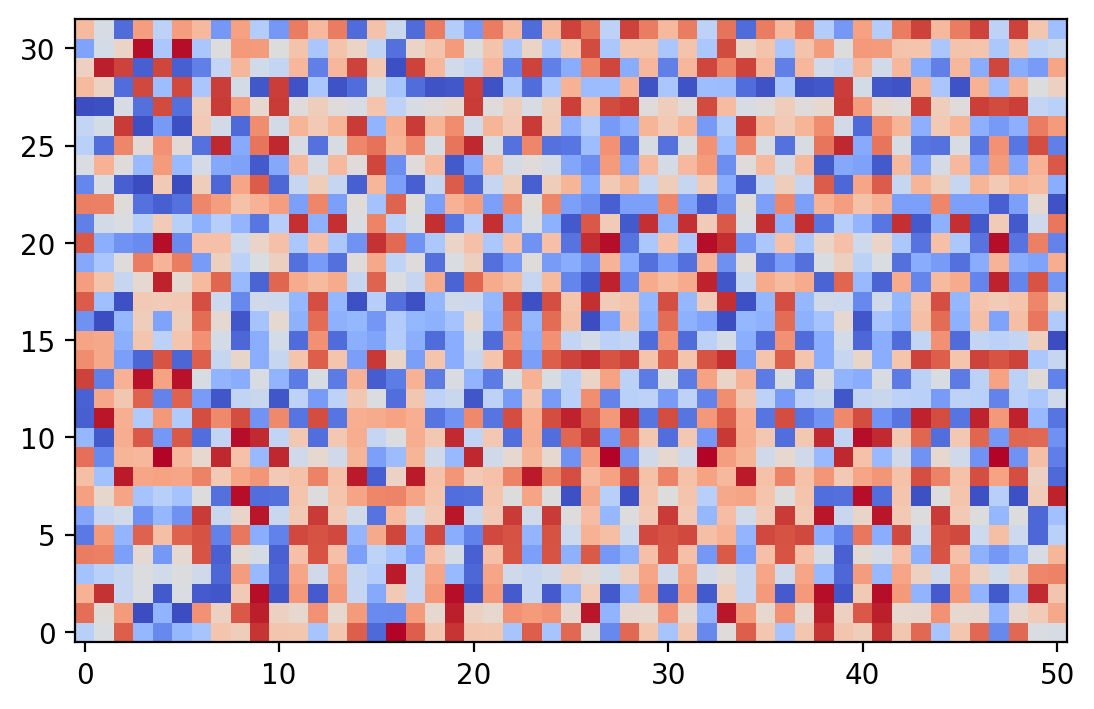

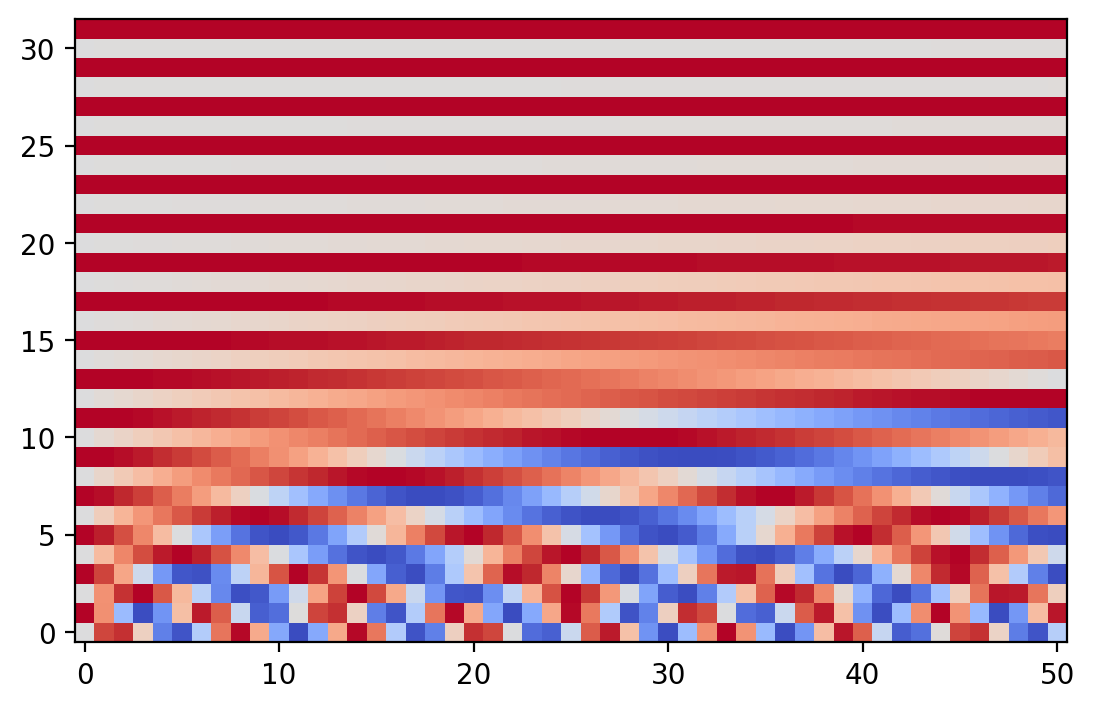

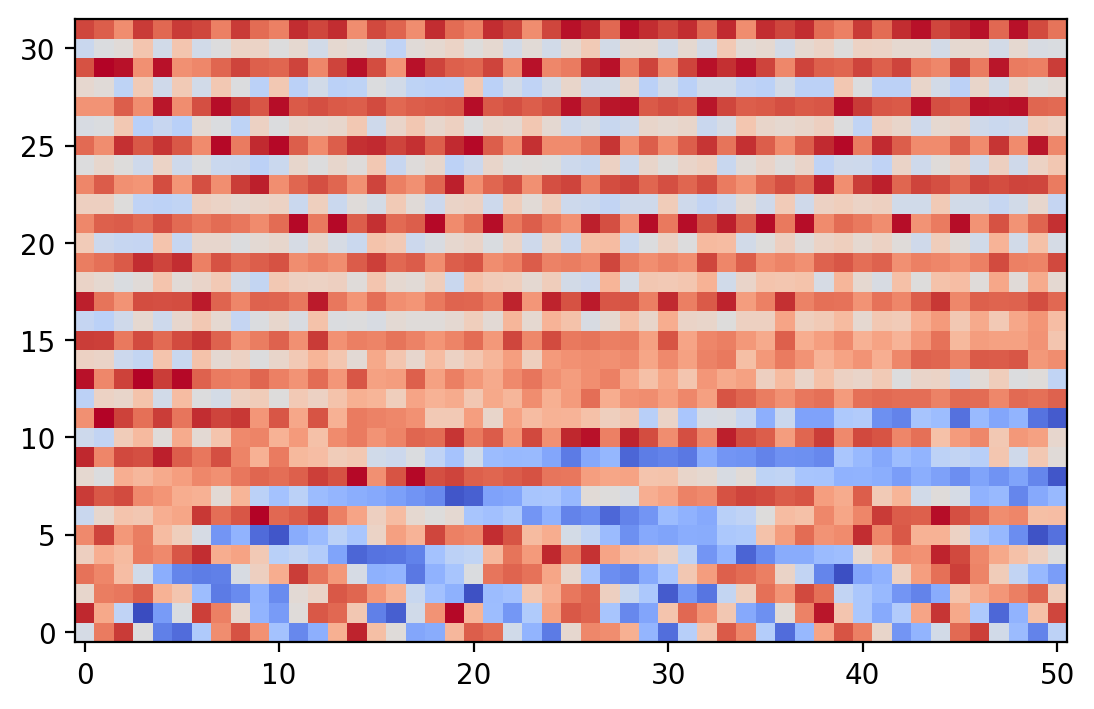

In [44]:
tpe = TokenAndPositionEmbedding(notes_vocab_size, 32)
token_embedding = tpe.token_emb(example_tokenised_notes)
position_embedding = tpe.pos_emb(token_embedding)
embedding = tpe(example_tokenised_notes)
plt.imshow(
    np.transpose(token_embedding),
    cmap="coolwarm",
    interpolation="nearest",
    origin="lower",
)
plt.show()
plt.imshow(
    np.transpose(position_embedding),
    cmap="coolwarm",
    interpolation="nearest",
    origin="lower",
)
plt.show()
plt.imshow(
    np.transpose(embedding),
    cmap="coolwarm",
    interpolation="nearest",
    origin="lower",
)
plt.show()

## 8. Build the Transformer model <a name="transformer_decoder"></a>

In [45]:
note_inputs = layers.Input(shape=(None,), dtype=tf.int32)
durations_inputs = layers.Input(shape=(None,), dtype=tf.int32)
note_embeddings = TokenAndPositionEmbedding(
    notes_vocab_size, EMBEDDING_DIM // 2
)(note_inputs)
duration_embeddings = TokenAndPositionEmbedding(
    durations_vocab_size, EMBEDDING_DIM // 2
)(durations_inputs)
embeddings = layers.Concatenate()([note_embeddings, duration_embeddings])
x, attention_scores = TransformerBlock(
    N_HEADS, KEY_DIM, EMBEDDING_DIM, FEED_FORWARD_DIM, name="attention"
)(embeddings)
note_outputs = layers.Dense(
    notes_vocab_size, activation="softmax", name="note_outputs"
)(x)
duration_outputs = layers.Dense(
    durations_vocab_size, activation="softmax", name="duration_outputs"
)(x)
model = models.Model(
    inputs=[note_inputs, durations_inputs],
    outputs=[note_outputs, duration_outputs],  # attention_scores
)
model.compile(
    "adam",
    loss=[
        losses.SparseCategoricalCrossentropy(),
        losses.SparseCategoricalCrossentropy(),
    ],
)
att_model = models.Model(
    inputs=[note_inputs, durations_inputs], outputs=attention_scores
)

In [46]:
model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_and_position… │ (None, None, 128) │      7,552 │ input_layer_2[0]… │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_and_position… │ (None, None, 128) │      3,072 │ input_layer_3[0]… │
│ (TokenAndPositionE… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, None, 256) │          0 │ token_and_positi… │
│ (Concatenate)       │                   │            │ token_and_positi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ [(None, None,     │  1,447,424 │ concatenate_1[0]… │
│ (TransformerBlock)  │ 256), (None, 5,   │            │                   │
│                     │ None, None)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ note_outputs        │ (None, None, 59)  │     15,163 │ attention[0][0]   │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ duration_outputs    │ (None, None, 24)  │      6,168 │ attention[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,479,379 (5.64 MB)

 Trainable params: 1,479,379 (5.64 MB)

 Non-trainable params: 0 (0.00 B)

In [47]:
if LOAD_MODEL:
    custom_objects = {
        "TokenAndPositionEmbedding": TokenAndPositionEmbedding,
        "TransformerBlock": TransformerBlock,
        "SinePositionEncoding": SinePositionEncoding,
    }
    if os.path.exists("./models/model.keras"):
        model = models.load_model(
            "./models/model.keras", custom_objects=custom_objects, compile=True
        )
    elif os.path.exists("./models/model"):
        model = models.load_model(
            "./models/model", custom_objects=custom_objects, compile=True
        )
    elif os.path.exists("./checkpoint/checkpoint.weights.h5"):
        model.load_weights("./checkpoint/checkpoint.weights.h5")
    elif os.path.exists("./checkpoint/checkpoint.ckpt"):
        model.load_weights("./checkpoint/checkpoint.ckpt")


## 9. Train the Transformer <a name="train"></a>

In [48]:
# Create a MusicGenerator checkpoint
class MusicGenerator(callbacks.Callback):
    def __init__(self, index_to_note, index_to_duration, top_k=10):
        self.index_to_note = index_to_note
        self.note_to_index = {
            note: index for index, note in enumerate(index_to_note)
        }
        self.index_to_duration = index_to_duration
        self.duration_to_index = {
            duration: index for index, duration in enumerate(index_to_duration)
        }

    def sample_from(self, probs, temperature):
        probs = probs ** (1 / temperature)
        probs = probs / np.sum(probs)
        return np.random.choice(len(probs), p=probs), probs

    def get_note(self, notes, durations, temperature):
        sample_note_idx = 1
        while sample_note_idx == 1:
            sample_note_idx, note_probs = self.sample_from(
                notes[0][-1], temperature
            )
            sample_note = self.index_to_note[sample_note_idx]

        sample_duration_idx = 1
        while sample_duration_idx == 1:
            sample_duration_idx, duration_probs = self.sample_from(
                durations[0][-1], temperature
            )
            sample_duration = self.index_to_duration[sample_duration_idx]

        new_note = get_midi_note(sample_note, sample_duration)

        return (
            new_note,
            sample_note_idx,
            sample_note,
            note_probs,
            sample_duration_idx,
            sample_duration,
            duration_probs,
        )

    def generate(self, start_notes, start_durations, max_tokens, temperature):
        attention_model = models.Model(
            inputs=self.model.input,
            outputs=self.model.get_layer("attention").output,
        )

        start_note_tokens = [self.note_to_index.get(x, 1) for x in start_notes]
        start_duration_tokens = [
            self.duration_to_index.get(x, 1) for x in start_durations
        ]
        sample_note = None
        sample_duration = None
        info = []
        midi_stream = music21.stream.Stream()

        midi_stream.append(music21.clef.BassClef())

        for sample_note, sample_duration in zip(start_notes, start_durations):
            new_note = get_midi_note(sample_note, sample_duration)
            if new_note is not None:
                midi_stream.append(new_note)

        while len(start_note_tokens) < max_tokens:
            x1 = np.array([start_note_tokens])
            x2 = np.array([start_duration_tokens])
            notes, durations = self.model.predict([x1, x2], verbose=0)

            repeat = True

            while repeat:
                (
                    new_note,
                    sample_note_idx,
                    sample_note,
                    note_probs,
                    sample_duration_idx,
                    sample_duration,
                    duration_probs,
                ) = self.get_note(notes, durations, temperature)

                if (
                    isinstance(new_note, music21.chord.Chord)
                    or isinstance(new_note, music21.note.Note)
                    or isinstance(new_note, music21.note.Rest)
                ) and sample_duration == "0.0":
                    repeat = True
                else:
                    repeat = False

            if new_note is not None:
                midi_stream.append(new_note)

            _, att = attention_model.predict([x1, x2], verbose=0)

            info.append(
                {
                    "prompt": [start_notes.copy(), start_durations.copy()],
                    "midi": midi_stream,
                    "chosen_note": (sample_note, sample_duration),
                    "note_probs": note_probs,
                    "duration_probs": duration_probs,
                    "atts": att[0, :, -1, :],
                }
            )
            start_note_tokens.append(sample_note_idx)
            start_duration_tokens.append(sample_duration_idx)
            start_notes.append(sample_note)
            start_durations.append(sample_duration)

            if sample_note == "START":
                break

        return info

    def on_epoch_end(self, epoch, logs=None):
        info = self.generate(
            ["START"], ["0.0"], max_tokens=GENERATE_LEN, temperature=0.5
        )
        midi_stream = info[-1]["midi"].chordify()
        print(info[-1]["prompt"])
        try:
            midi_stream.show()
        except Exception:
            pass
        output_dir = os.path.join(
            repo_root, "notebooks", "11_music", "01_transformer", "output"
        )
        os.makedirs(output_dir, exist_ok=True)
        midi_stream.write(
            "midi",
            fp=os.path.join(
                output_dir,
                "output-" + str(epoch).zfill(4) + ".mid",
            ),
        )


In [49]:
# Create directories for checkpoints, logs, and models
os.makedirs("./checkpoint", exist_ok=True)
os.makedirs("./logs", exist_ok=True)
os.makedirs("./models", exist_ok=True)

# Create a model save checkpoint
checkpoint_path = "./checkpoint/checkpoint.weights.h5" if tf.__version__ >= "2.16" else "./checkpoint/checkpoint.ckpt"
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    save_weights_only=True,
    save_freq="epoch",
    verbose=0,
)

tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")

# Tokenize starting prompt
music_generator = MusicGenerator(notes_vocab, durations_vocab)


In [50]:
model.fit(
    ds,
    epochs=EPOCHS,
    callbacks=[
        model_checkpoint_callback,
        tensorboard_callback,
        music_generator,
    ],
)

Epoch 1/50
102/107 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - duration_outputs_loss: 1.3481 - loss: 4.9409 - note_outputs_loss: 3.5928

[['START', np.str_('C4'), np.str_('B3'), np.str_('A3'), np.str_('G3'), np.str_('D4'), np.str_('C4'), np.str_('A3'), np.str_('D4'), np.str_('D4'), np.str_('C4'), np.str_('D4'), np.str_('D4'), np.str_('D4'), np.str_('E4'), np.str_('G4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('A4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('C#4'), np.str_('E4'), np.str_('G4'), np.str_('C#4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('F#4'), np.str_('A4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4'), np.str_('E4')], ['0.0', np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), np.str_('0.5'), n

In [51]:
# Save the final model
os.makedirs("./models", exist_ok=True)
try:
    model.save("./models/model.keras")
except Exception:
    model.save("./models/model")


# 3. Generate music using the Transformer

In [52]:
info = music_generator.generate(
    ["START"], ["0.0"], max_tokens=50, temperature=0.5
)
midi_stream = info[-1]["midi"].chordify()
try:
    midi_stream.show()
except Exception as e:
    print(f"Graphical sheet music viewer not available ({e}). Showing as text:")
    midi_stream.show("text")


Graphical sheet music viewer not available (Cannot find a path to the 'mscore' file at /usr/bin/mscore3 -- download MuseScore). Showing as text:
{0.0} <music21.clef.BassClef>
{0.0} <music21.key.Key of E- major>
{0.0} <music21.meter.TimeSignature 4/4>
{0.0} <music21.note.Rest 16th>
{0.25} <music21.chord.Chord G3>
{0.5} <music21.chord.Chord E-4>
{0.75} <music21.chord.Chord D4>
{1.0} <music21.chord.Chord C4>
{1.25} <music21.chord.Chord B3>
{1.5} <music21.chord.Chord C4>
{1.75} <music21.chord.Chord B3>
{2.0} <music21.chord.Chord A3>
{2.25} <music21.chord.Chord G3>
{2.5} <music21.chord.Chord F#3>
{2.75} <music21.chord.Chord G3>
{3.5} <music21.chord.Chord A3>
{3.75} <music21.chord.Chord D3>
{4.0} <music21.chord.Chord F#3>
{4.25} <music21.chord.Chord G3>
{4.5} <music21.chord.Chord D3>
{4.75} <music21.chord.Chord G2>
{5.0} <music21.chord.Chord B3>
{5.25} <music21.chord.Chord C4>
{5.5} <music21.chord.Chord D4>
{5.75} <music21.chord.Chord G2>
{6.0} <music21.chord.Chord B3>
{6.25} <music21.chord.

## Write music to MIDI file

In [53]:
timestr = time.strftime("%Y%m%d-%H%M%S")
output_dir = os.path.join(
    repo_root, "notebooks", "11_music", "01_transformer", "output"
)
os.makedirs(output_dir, exist_ok=True)
midi_stream.write(
    "midi",
    fp=os.path.join(
        output_dir,
        "output-" + timestr + ".mid",
    ),
)


'/content/Generative_Deep_Learning_2nd_Edition/notebooks/11_music/01_transformer/output/output-20261115-042610.mid'

## Note probabilities

In [54]:
max_pitch = 70
seq_len = len(info)
grid = np.zeros((max_pitch, seq_len), dtype=np.float32)

for j in range(seq_len):
    for i, prob in enumerate(info[j]["note_probs"]):
        try:
            pitch = music21.note.Note(notes_vocab[i]).pitch.midi
            grid[pitch, j] = prob
        except:
            pass  # Don't show key / time signatures

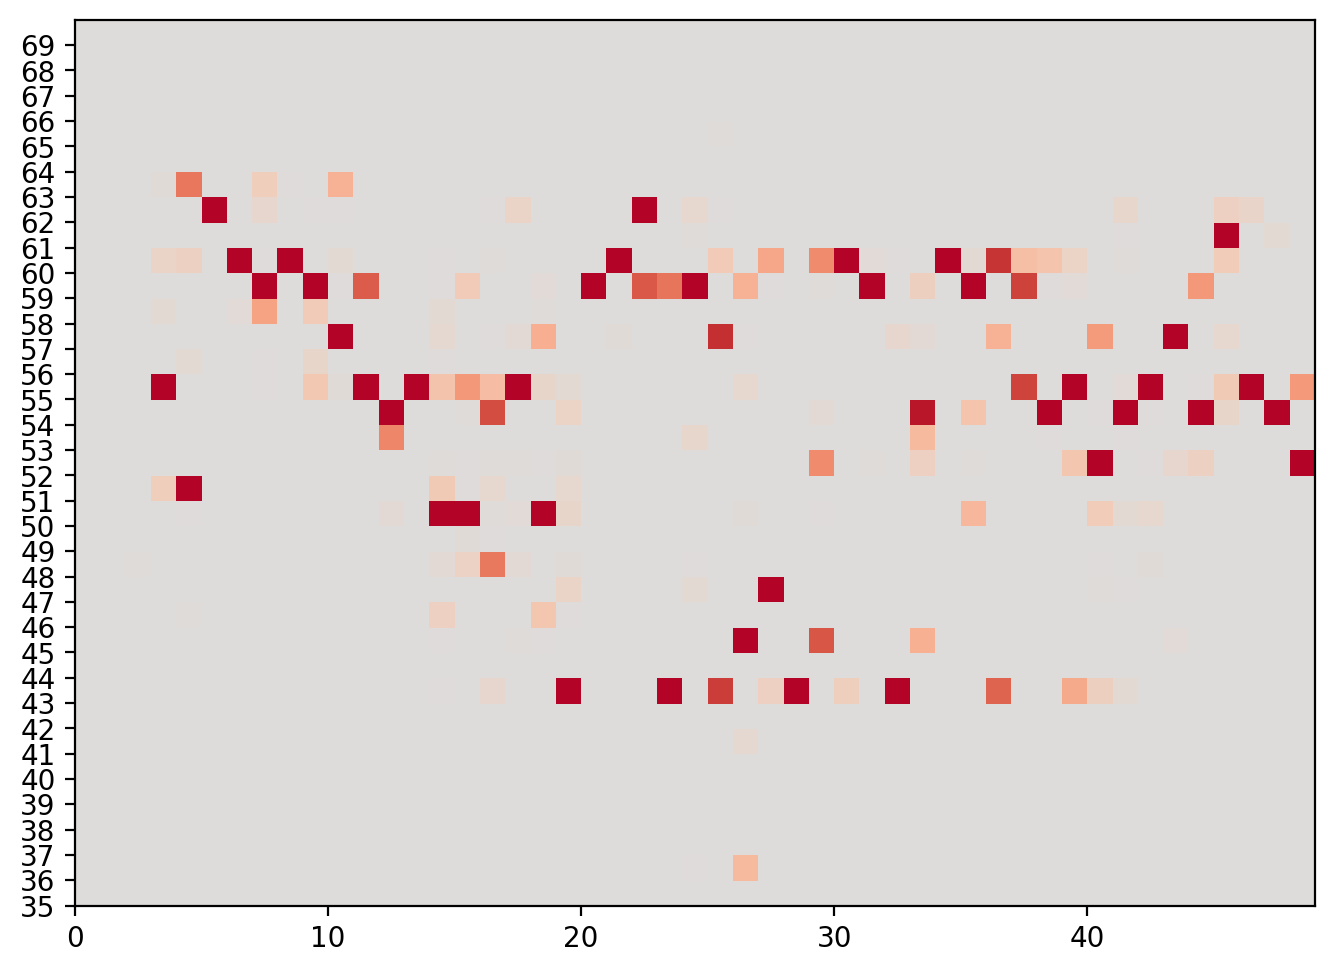

In [55]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.set_yticks([int(j) for j in range(35, 70)])
plt.imshow(
    grid[35:70, :],
    origin="lower",
    cmap="coolwarm",
    vmin=-0.5,
    vmax=0.5,
    extent=[0, seq_len, 35, 70],
)
plt.show()

## Attention Plot

In [56]:
plot_size = 20

att_matrix = np.zeros((plot_size, plot_size))
prediction_output = []
last_prompt = []

In [57]:
for j in range(plot_size):
    atts = info[j]["atts"].max(axis=0)
    att_matrix[: (j + 1), j] = atts
    prediction_output.append(info[j]["chosen_note"][0])
    last_prompt.append(info[j]["prompt"][0][-1])

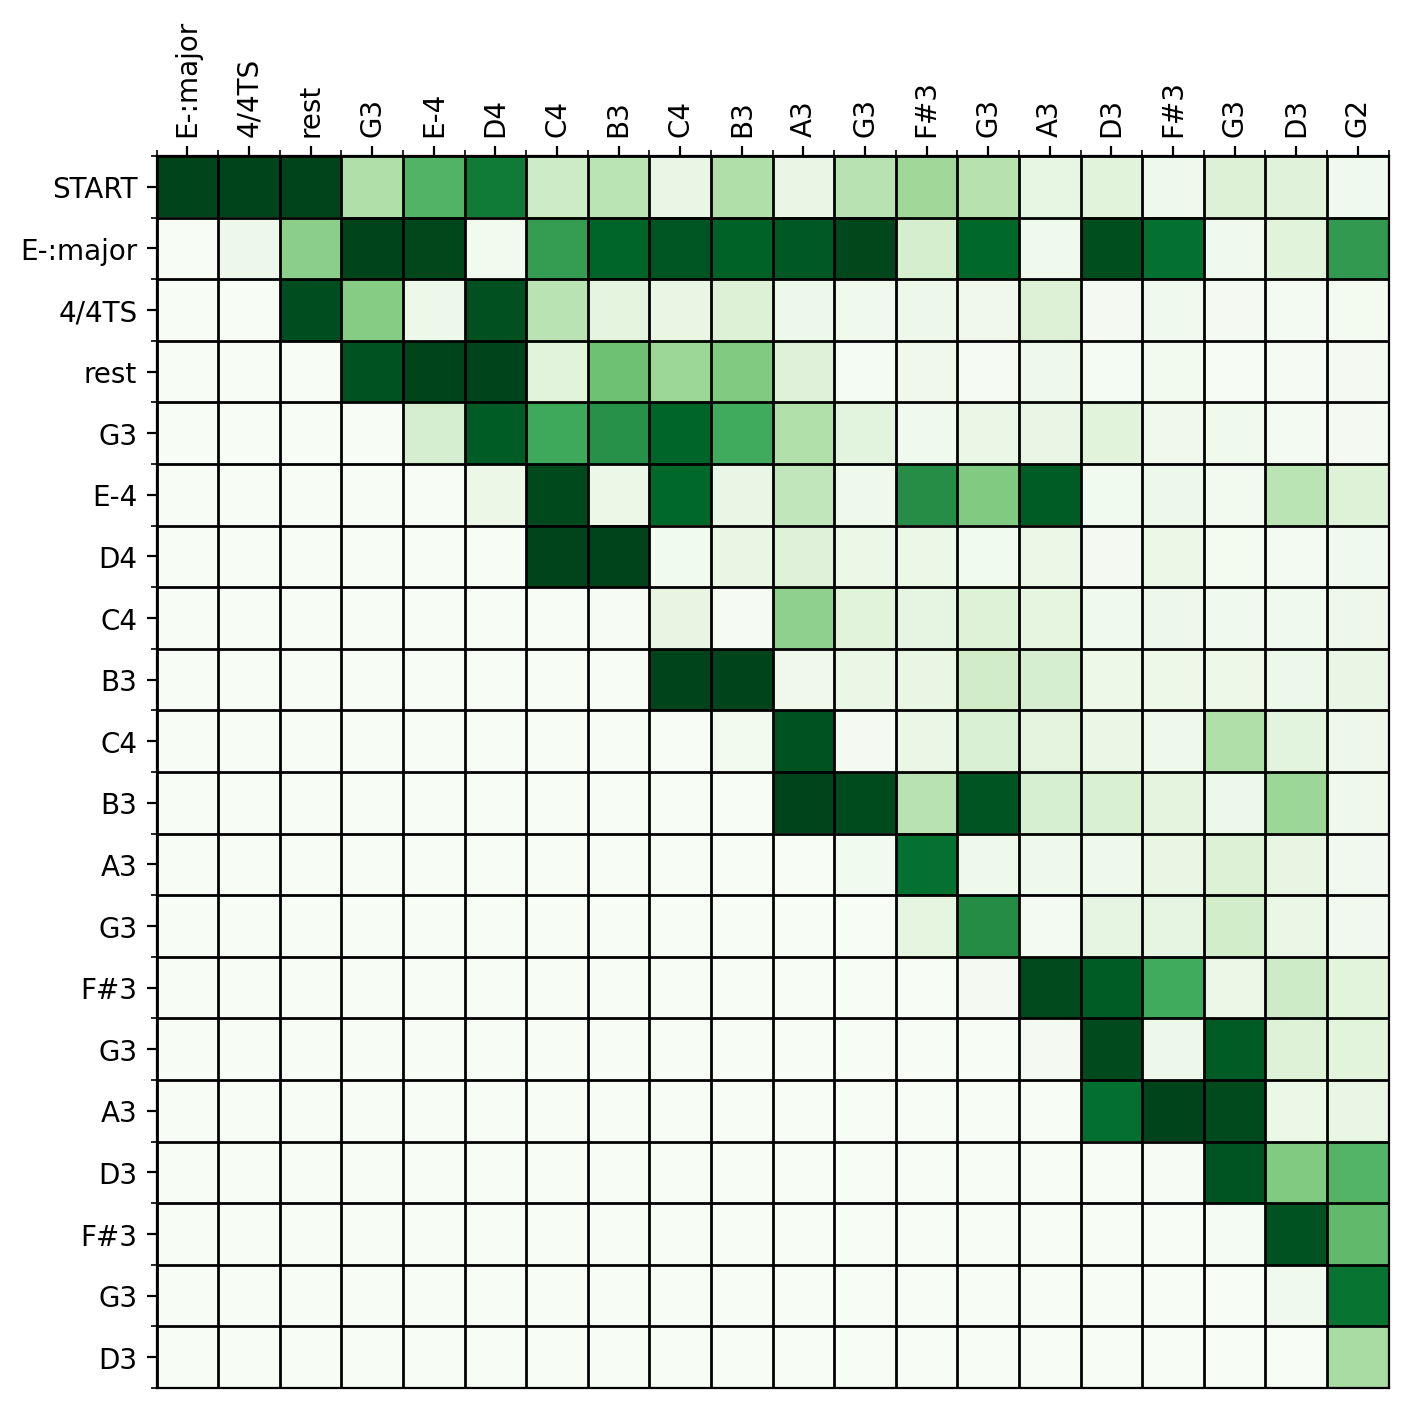

In [58]:
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(att_matrix, cmap="Greens", interpolation="nearest")

ax.set_xticks(np.arange(-0.5, plot_size, 1), minor=True)
ax.set_yticks(np.arange(-0.5, plot_size, 1), minor=True)
ax.grid(which="minor", color="black", linestyle="-", linewidth=1)
ax.set_xticks(np.arange(plot_size))
ax.set_yticks(np.arange(plot_size))
ax.set_xticklabels(prediction_output[:plot_size])
ax.set_yticklabels(last_prompt[:plot_size])
ax.xaxis.tick_top()

plt.setp(
    ax.get_xticklabels(),
    rotation=90,
    ha="left",
    va="center",
    rotation_mode="anchor",
)
plt.show()